# Phase F: Collision-prediction baselines

**Question:** which signals TF++ itself produces can predict an upcoming collision, how early, and does **temporal history** add anything beyond **current-frame** information?

| Monitor | Inputs (all TF++-observable) | Purpose |
|---|---|---|
| Speed only | Ego speed | Minimal baseline |
| TF++ confidence | Speed, target speed, speed-head entropy, top-class margin, top probability | Single-frame confidence |
| Handcrafted temporal | Speed plus 1–2 s statistics: path disagreement and jitter, target-speed JS divergence, entropy change, steering variation and reversals, pedal switches, jerk, speed-tracking gap, route alignment | The professor's requested baseline |
| Current-frame geometry | Speed plus **TF++'s own planned path** (timed by its target speed) checked against its **tracked boxes** (constant velocity): TTC, minimum clearance, time gap, conflict flag; nearest box in the lane ahead and closing speed; TF++'s `bb_in_front` flag | Strong, intent-aware geometric baseline |
| Geometry + temporal | Both of the above, plus 1 s geometric trends | Do they complement each other? |
| Current frame (geometry + confidence) | Geometry and confidence together | The strongest current-frame model |
| Current frame + temporal | The row above plus temporal history | **Does history add value beyond current-frame geometry and confidence?** |

A small GRU is out of scope here; see Phase G.

**Protocol**

- **Label:** a step is positive if a collision counted by the leaderboard happens within 3 s.
- **Models:** logistic regression, standardised and class-balanced.
- **Splits:** 5-fold cross-validation **grouped by route**.
- **Thresholds:** chosen **on validation data only**, using an inner route-grouped split inside each training fold.
- **Alarm-time budget:** each threshold is set so the monitor is in alarm for **1%, 2% or 5% of normal driving time**, so every monitor gets the same budget. Metrics are then measured on the untouched test routes.
- **Reported:** moving-step AUROC/AUPRC; recall of collision *events* warned ≥1 s and ≥2 s ahead; false-alarm onsets per minute; mean false-alarm duration; and the lead-time distribution.
- **Confidence intervals:** brackets are 95% route-level bootstrap intervals.

With about 60 collisions, differences under about 12 points are not conclusive.

In [1]:
import sys, csv, json, collections, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import ew_analysis as ew
import fg_analysis as fg

RESULTS = REPO / "results" / "bench2drive_v2"
OUT = RESULTS / "fg"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def table(rows, cols=None):
    cols = cols or list(rows[0])
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        out.append("| " + " | ".join(f"{r[c]:.3f}" if isinstance(r.get(c), float) else str(r.get(c, "")) for c in cols) + " |")
    display(Markdown("\n".join(out)))

def save_csv(name, rows):
    with open(OUT / f"{name}.csv", "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)

p = lambda v: f"{100 * v:.0f}%"
pci = lambda v, c: f"{100 * v:.0f}% [{100 * c[0]:.0f}, {100 * c[1]:.0f}]"

# dataset: one row per 20 Hz step, label = a counted collision within 3 s (built by ew_analysis, unchanged)
routes, ckpts, EW = ew.build_cache(RESULTS, REPO / "carla_garage/leaderboard/data/bench2drive220.xml", RESULTS / "early_warning" / "cache.pkl")
events = ew.event_table(routes, ckpts, EW)
F, M, ev_index, untimed = ew.build_dataset(routes, ckpts, EW, events)
EIDS = sorted({e["eid"] for e in ev_index})
G = M["route"]
print(f"routes {len(np.unique(G))} | steps {len(M['y']):,} | positive steps {M['y'].sum():,} | moving steps {M['moving'].sum():,}")
print(f"collision events {len(EIDS)} | normal driving {(M['y'] == 0).sum() * ew.DT / 60:.0f} min | excluded (off-route only, no timestamp): {untimed}")

routes 214 | steps 147,531 | positive steps 3,042 | moving steps 43,506
collision events 60 | normal driving 120 min | excluded (off-route only, no timestamp): ['2790', '23658', '23910', '24098', '25896']


## 1. Train and evaluate every monitor

In [2]:
MODELS = {
    "Speed only": fg.SPEED,
    "TF++ confidence": fg.CONFIDENCE,
    "Handcrafted temporal": fg.temporal(),
    "Current-frame geometry (intent-aware)": fg.GEOMETRY,
    "Geometry + temporal": fg.GEOMETRY_TEMPORAL,
    "Current frame (geometry + confidence)": fg.GEOMETRY + fg.CONFIDENCE,
    "Current frame + temporal": fg.GEOMETRY + fg.CONFIDENCE + fg.temporal()[1:] + ew.TEMPORAL_GEOM,
}
t0 = time.time()
S, R = {}, {}
for name, cols in MODELS.items():
    score, thr = fg.cross_validate(fg.design(F, cols), M["y"], G)
    S[name] = (score, thr)
    auc, ap = fg.ranking(score, M)
    R[name] = {"auroc": auc, "auprc": ap, "ci": fg.bootstrap(score, thr, M, EIDS),
               **{b: fg.alarm_metrics(score, thr[b], M, EIDS) for b in fg.BUDGETS}}
    print(f"{name:42s} AUROC {auc:.3f}  recall>=1s @2%: {R[name][0.02]['recall_1s']:.0%}  ({time.time() - t0:.0f} s)")

Speed only                                 AUROC 0.626  recall>=1s @2%: 27%  (10 s)


TF++ confidence                            AUROC 0.641  recall>=1s @2%: 27%  (19 s)


Handcrafted temporal                       AUROC 0.730  recall>=1s @2%: 32%  (31 s)


Current-frame geometry (intent-aware)      AUROC 0.716  recall>=1s @2%: 42%  (41 s)


Geometry + temporal                        AUROC 0.757  recall>=1s @2%: 52%  (57 s)


Current frame (geometry + confidence)      AUROC 0.749  recall>=1s @2%: 42%  (69 s)


Current frame + temporal                   AUROC 0.760  recall>=1s @2%: 48%  (88 s)


## 2. Results

In [3]:
rows = []
for name, r in R.items():
    c = r["ci"]
    rows.append({"monitor": name, "AUROC (moving)": f"{r['auroc']:.3f} [{c['auroc'][0]:.3f}, {c['auroc'][1]:.3f}]",
                 "AUPRC (moving)": f"{r['auprc']:.3f} [{c['auprc'][0]:.3f}, {c['auprc'][1]:.3f}]"})
display(Markdown(f"**Ranking quality.** Base rate: {M['y'][M['moving']].mean():.1%} of moving steps are within 3 s of a collision."))
table(rows)
save_csv("F_ranking", rows)

for b in fg.BUDGETS:
    rows = []
    for name, r in R.items():
        a, c = r[b], r["ci"]
        rows.append({"monitor": name, "warned >= 1 s": pci(a["recall_1s"], c[f"recall_1s@{b}"]),
                     "warned >= 2 s": pci(a["recall_2s"], c[f"recall_2s@{b}"]),
                     "median lead (s)": f"{a['median_lead']:.2f}",
                     "time in alarm (test)": f"{100 * a['alarm_time']:.1f}%",
                     "false-alarm onsets / min": f"{a['onsets_per_min']:.2f} [{c[f'onsets@{b}'][0]:.2f}, {c[f'onsets@{b}'][1]:.2f}]",
                     "mean false alarm (s)": f"{a['mean_false_alarm_s']:.1f}"})
    display(Markdown(f"**Alarm-time budget {b:.0%}** (threshold chosen on validation routes; measured on test routes)"))
    table(rows)
    save_csv(f"F_budget_{int(b * 100)}pct", rows)

**Ranking quality.** Base rate: 5.7% of moving steps are within 3 s of a collision.

| monitor | AUROC (moving) | AUPRC (moving) |
|---|---|---|
| Speed only | 0.626 [0.562, 0.687] | 0.099 [0.068, 0.147] |
| TF++ confidence | 0.641 [0.578, 0.704] | 0.104 [0.071, 0.153] |
| Handcrafted temporal | 0.730 [0.670, 0.780] | 0.122 [0.081, 0.167] |
| Current-frame geometry (intent-aware) | 0.716 [0.662, 0.766] | 0.205 [0.140, 0.276] |
| Geometry + temporal | 0.757 [0.706, 0.807] | 0.220 [0.151, 0.294] |
| Current frame (geometry + confidence) | 0.749 [0.697, 0.795] | 0.223 [0.159, 0.294] |
| Current frame + temporal | 0.760 [0.707, 0.810] | 0.221 [0.151, 0.296] |

**Alarm-time budget 1%** (threshold chosen on validation routes; measured on test routes)

| monitor | warned >= 1 s | warned >= 2 s | median lead (s) | time in alarm (test) | false-alarm onsets / min | mean false alarm (s) |
|---|---|---|---|---|---|---|
| Speed only | 15% [6, 23] | 5% [0, 11] | 0.00 | 1.0% | 0.47 [0.31, 0.65] | 1.3 |
| TF++ confidence | 18% [11, 28] | 7% [1, 14] | 0.00 | 0.9% | 0.43 [0.29, 0.60] | 1.4 |
| Handcrafted temporal | 15% [6, 26] | 5% [0, 12] | 0.00 | 0.8% | 0.83 [0.61, 1.09] | 0.6 |
| Current-frame geometry (intent-aware) | 33% [23, 44] | 10% [3, 18] | 0.60 | 0.9% | 0.89 [0.68, 1.13] | 0.6 |
| Geometry + temporal | 28% [18, 39] | 10% [3, 19] | 0.50 | 0.7% | 1.10 [0.81, 1.41] | 0.4 |
| Current frame (geometry + confidence) | 32% [22, 42] | 10% [3, 18] | 0.58 | 0.8% | 1.20 [0.64, 2.18] | 0.5 |
| Current frame + temporal | 28% [17, 40] | 10% [3, 19] | 0.58 | 0.7% | 1.09 [0.82, 1.44] | 0.4 |

**Alarm-time budget 2%** (threshold chosen on validation routes; measured on test routes)

| monitor | warned >= 1 s | warned >= 2 s | median lead (s) | time in alarm (test) | false-alarm onsets / min | mean false alarm (s) |
|---|---|---|---|---|---|---|
| Speed only | 27% [17, 37] | 13% [6, 22] | 0.00 | 2.0% | 0.79 [0.58, 1.05] | 1.6 |
| TF++ confidence | 27% [17, 37] | 15% [7, 24] | 0.00 | 1.9% | 0.79 [0.58, 1.07] | 1.5 |
| Handcrafted temporal | 32% [20, 44] | 18% [9, 29] | 0.55 | 1.8% | 1.54 [1.17, 1.97] | 0.7 |
| Current-frame geometry (intent-aware) | 42% [31, 53] | 12% [4, 19] | 0.78 | 1.8% | 1.60 [1.26, 2.00] | 0.7 |
| Geometry + temporal | 52% [38, 65] | 17% [8, 27] | 1.02 | 1.5% | 1.97 [1.48, 2.48] | 0.5 |
| Current frame (geometry + confidence) | 42% [30, 53] | 12% [4, 20] | 0.75 | 1.5% | 1.80 [1.11, 2.97] | 0.5 |
| Current frame + temporal | 48% [34, 61] | 17% [8, 26] | 0.85 | 1.5% | 1.95 [1.51, 2.43] | 0.5 |

**Alarm-time budget 5%** (threshold chosen on validation routes; measured on test routes)

| monitor | warned >= 1 s | warned >= 2 s | median lead (s) | time in alarm (test) | false-alarm onsets / min | mean false alarm (s) |
|---|---|---|---|---|---|---|
| Speed only | 50% [38, 65] | 28% [18, 39] | 0.93 | 5.0% | 1.78 [1.35, 2.26] | 1.8 |
| TF++ confidence | 48% [37, 62] | 32% [20, 43] | 0.90 | 4.6% | 1.47 [1.11, 1.92] | 2.0 |
| Handcrafted temporal | 62% [50, 73] | 35% [25, 46] | 1.27 | 4.8% | 2.81 [2.23, 3.50] | 1.1 |
| Current-frame geometry (intent-aware) | 62% [51, 74] | 27% [16, 39] | 1.25 | 5.1% | 3.83 [2.80, 5.08] | 0.8 |
| Geometry + temporal | 67% [55, 78] | 38% [27, 50] | 1.50 | 4.5% | 3.43 [2.63, 4.36] | 0.8 |
| Current frame (geometry + confidence) | 58% [47, 70] | 30% [21, 40] | 1.23 | 6.2% | 2.81 [2.03, 3.91] | 1.4 |
| Current frame + temporal | 65% [53, 76] | 37% [25, 49] | 1.50 | 4.4% | 3.44 [2.70, 4.29] | 0.8 |

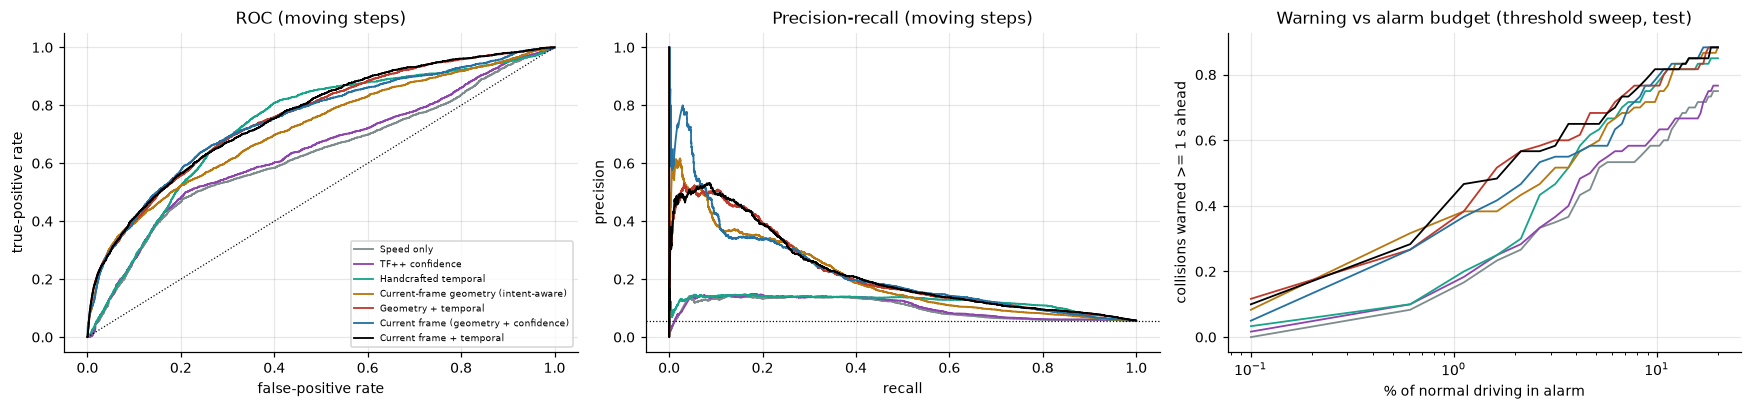

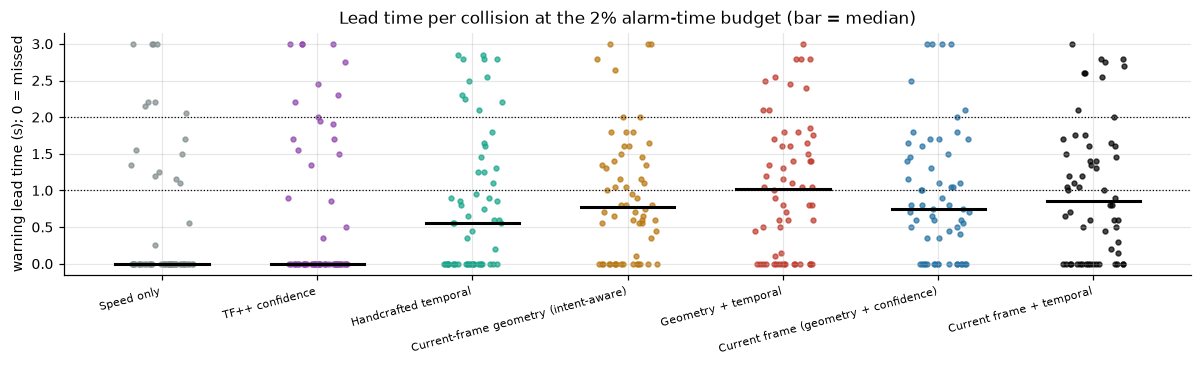

In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve
COL = dict(zip(MODELS, ["#7f8c8d", "#8e44ad", "#17a589", "#b9770e", "#c0392b", "#2471a3", "#000000"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
mv = M["moving"]
for name, (score, thr) in S.items():
    fpr, tpr, _ = roc_curve(M["y"][mv], score[mv]); axes[0].plot(fpr, tpr, color=COL[name], lw=1.2, label=name)
    pr, rc, _ = precision_recall_curve(M["y"][mv], score[mv]); axes[1].plot(rc, pr, color=COL[name], lw=1.2)
    neg = M["y"] == 0
    pts = []
    for q in np.linspace(0.80, 0.999, 40):
        t = np.quantile(score[neg], q)
        a = fg.alarm_metrics(score, np.full(len(score), t), M, EIDS)
        pts.append((a["alarm_time"], a["recall_1s"]))
    pts = np.array(pts); axes[2].plot(100 * pts[:, 0], pts[:, 1], color=COL[name], lw=1.2)
axes[0].plot([0, 1], [0, 1], "k:", lw=0.8); axes[0].set_xlabel("false-positive rate"); axes[0].set_ylabel("true-positive rate")
axes[0].set_title("ROC (moving steps)"); axes[0].legend(fontsize=6)
axes[1].axhline(M["y"][mv].mean(), color="k", ls=":", lw=0.8); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision-recall (moving steps)")
axes[2].set_xscale("log"); axes[2].set_xlabel("% of normal driving in alarm"); axes[2].set_ylabel("collisions warned >= 1 s ahead")
axes[2].set_title("Warning vs alarm budget (threshold sweep, test)")
plt.tight_layout(); plt.savefig(FIG / "F_curves.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.4))
for i, name in enumerate(MODELS):
    lv = np.array(list(R[name][0.02]["lead"].values()))
    ax.scatter(i + np.random.default_rng(i).uniform(-0.2, 0.2, len(lv)), lv, s=10, color=COL[name], alpha=0.7)
    ax.plot([i - 0.3, i + 0.3], [np.median(lv)] * 2, color="k", lw=2)
ax.set_xticks(range(len(MODELS)), list(MODELS), rotation=15, ha="right", fontsize=7)
ax.axhline(1, color="k", ls=":", lw=0.8); ax.axhline(2, color="k", ls=":", lw=0.8)
ax.set_ylabel("warning lead time (s); 0 = missed"); ax.set_title("Lead time per collision at the 2% alarm-time budget (bar = median)")
plt.tight_layout(); plt.savefig(FIG / "F_lead_times.png", bbox_inches="tight"); plt.show()

## 3. The main comparison: does temporal history add value?

This is a **paired** route-bootstrap of the difference (A − B). Both monitors are evaluated on the same test routes, each with its own validated threshold. A 95% interval that excludes 0 indicates a real difference.

In [5]:
rows = []
for a, b in (("Geometry + temporal", "Current-frame geometry (intent-aware)"),
             ("Current frame + temporal", "Current frame (geometry + confidence)"),
             ("Handcrafted temporal", "TF++ confidence"),
             ("Handcrafted temporal", "Speed only"),
             ("Current-frame geometry (intent-aware)", "Speed only")):
    d = fg.paired_difference(*S[a], *S[b], M, EIDS)
    for k, (pt, lo, hi) in d.items():
        rows.append({"A minus B": f"{a}  minus  {b}", "metric": k, "difference": f"{pt:+.3f}",
                     "95% CI": f"[{lo:+.3f}, {hi:+.3f}]", "excludes 0": "yes" if lo > 0 or hi < 0 else ""})
table(rows)
save_csv("F_paired_differences", rows)

| A minus B | metric | difference | 95% CI | excludes 0 |
|---|---|---|---|---|
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | AUPRC (moving) | +0.015 | [-0.044, +0.071] |  |
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | recall >=1 s @ 1% | -0.050 | [-0.178, +0.055] |  |
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | recall >=2 s @ 1% | +0.000 | [-0.096, +0.084] |  |
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | recall >=1 s @ 2% | +0.100 | [-0.017, +0.215] |  |
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | recall >=2 s @ 2% | +0.050 | [-0.056, +0.150] |  |
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | recall >=1 s @ 5% | +0.050 | [-0.059, +0.145] |  |
| Geometry + temporal  minus  Current-frame geometry (intent-aware) | recall >=2 s @ 5% | +0.117 | [+0.024, +0.204] | yes |
| Current frame + temporal  minus  Current frame (geometry + confidence) | AUPRC (moving) | -0.002 | [-0.057, +0.046] |  |
| Current frame + temporal  minus  Current frame (geometry + confidence) | recall >=1 s @ 1% | -0.033 | [-0.154, +0.067] |  |
| Current frame + temporal  minus  Current frame (geometry + confidence) | recall >=2 s @ 1% | +0.000 | [-0.077, +0.073] |  |
| Current frame + temporal  minus  Current frame (geometry + confidence) | recall >=1 s @ 2% | +0.067 | [-0.059, +0.186] |  |
| Current frame + temporal  minus  Current frame (geometry + confidence) | recall >=2 s @ 2% | +0.050 | [-0.047, +0.136] |  |
| Current frame + temporal  minus  Current frame (geometry + confidence) | recall >=1 s @ 5% | +0.067 | [-0.051, +0.183] |  |
| Current frame + temporal  minus  Current frame (geometry + confidence) | recall >=2 s @ 5% | +0.067 | [-0.019, +0.159] |  |
| Handcrafted temporal  minus  TF++ confidence | AUPRC (moving) | +0.018 | [-0.028, +0.050] |  |
| Handcrafted temporal  minus  TF++ confidence | recall >=1 s @ 1% | -0.033 | [-0.170, +0.097] |  |
| Handcrafted temporal  minus  TF++ confidence | recall >=2 s @ 1% | -0.017 | [-0.088, +0.058] |  |
| Handcrafted temporal  minus  TF++ confidence | recall >=1 s @ 2% | +0.050 | [-0.094, +0.174] |  |
| Handcrafted temporal  minus  TF++ confidence | recall >=2 s @ 2% | +0.033 | [-0.100, +0.140] |  |
| Handcrafted temporal  minus  TF++ confidence | recall >=1 s @ 5% | +0.133 | [+0.000, +0.266] |  |
| Handcrafted temporal  minus  TF++ confidence | recall >=2 s @ 5% | +0.033 | [-0.089, +0.158] |  |
| Handcrafted temporal  minus  Speed only | AUPRC (moving) | +0.023 | [-0.023, +0.054] |  |
| Handcrafted temporal  minus  Speed only | recall >=1 s @ 1% | +0.000 | [-0.134, +0.125] |  |
| Handcrafted temporal  minus  Speed only | recall >=2 s @ 1% | +0.000 | [-0.071, +0.068] |  |
| Handcrafted temporal  minus  Speed only | recall >=1 s @ 2% | +0.050 | [-0.102, +0.173] |  |
| Handcrafted temporal  minus  Speed only | recall >=2 s @ 2% | +0.050 | [-0.070, +0.155] |  |
| Handcrafted temporal  minus  Speed only | recall >=1 s @ 5% | +0.117 | [-0.018, +0.265] |  |
| Handcrafted temporal  minus  Speed only | recall >=2 s @ 5% | +0.067 | [-0.055, +0.195] |  |
| Current-frame geometry (intent-aware)  minus  Speed only | AUPRC (moving) | +0.105 | [+0.058, +0.154] | yes |
| Current-frame geometry (intent-aware)  minus  Speed only | recall >=1 s @ 1% | +0.183 | [+0.088, +0.284] | yes |
| Current-frame geometry (intent-aware)  minus  Speed only | recall >=2 s @ 1% | +0.050 | [+0.000, +0.109] |  |
| Current-frame geometry (intent-aware)  minus  Speed only | recall >=1 s @ 2% | +0.150 | [+0.029, +0.266] | yes |
| Current-frame geometry (intent-aware)  minus  Speed only | recall >=2 s @ 2% | -0.017 | [-0.088, +0.056] |  |
| Current-frame geometry (intent-aware)  minus  Speed only | recall >=1 s @ 5% | +0.117 | [-0.008, +0.252] |  |
| Current-frame geometry (intent-aware)  minus  Speed only | recall >=2 s @ 5% | -0.017 | [-0.126, +0.094] |  |

## 4. By scenario family (2% alarm-time budget, warned ≥ 1 s ahead)

In [6]:
fam_of_eid = {e["eid"]: e["family"] for e in ev_index}
rows = []
for name in MODELS:
    lead = R[name][0.02]["lead"]
    r = {"monitor": name}
    for f in ("junction", "lane_merge", "obstacle_detour", "vru_crossing", "cut_in_hazard"):
        es = [e for e in EIDS if fam_of_eid[e] == f]
        r[f"{f} (n={len(es)})"] = f"{sum(lead[e] >= 1 for e in es)}/{len(es)}"
    rows.append(r)
table(rows)
save_csv("F_by_family", rows)

| monitor | junction (n=13) | lane_merge (n=18) | obstacle_detour (n=21) | vru_crossing (n=5) | cut_in_hazard (n=3) |
|---|---|---|---|---|---|
| Speed only | 1/13 | 4/18 | 8/21 | 3/5 | 0/3 |
| TF++ confidence | 1/13 | 5/18 | 7/21 | 3/5 | 0/3 |
| Handcrafted temporal | 2/13 | 6/18 | 8/21 | 2/5 | 1/3 |
| Current-frame geometry (intent-aware) | 5/13 | 5/18 | 12/21 | 2/5 | 1/3 |
| Geometry + temporal | 8/13 | 8/18 | 12/21 | 2/5 | 1/3 |
| Current frame (geometry + confidence) | 4/13 | 6/18 | 12/21 | 2/5 | 1/3 |
| Current frame + temporal | 8/13 | 7/18 | 12/21 | 1/5 | 1/3 |

## Takeaways

There are 60 collisions on 214 routes, with 120 minutes of normal driving. Models are logistic regression with thresholds chosen on validation routes. At the 2% budget, monitors raise about 1.5–2 false alarms per minute, each lasting about 0.5 s.

**1. Ranking**

| Monitor | AUROC (moving) | AUPRC (moving) |
|---|---|---|
| Speed only | 0.63 | 0.10 |
| TF++ confidence | 0.64 | 0.10 |
| Handcrafted temporal | 0.73 | 0.12 |
| Intent-aware geometry | 0.72 | **0.21** |
| Geometry + temporal | 0.76 | 0.22 |
| Current frame (geometry + confidence) | 0.75 | 0.22 |
| Current frame + temporal | 0.76 | 0.22 |

Only geometry lifts precision (AUPRC) clearly above the speed baseline.

**2. Early warning: collisions warned ≥1 s / ≥2 s ahead**

| Monitor | @1% | @2% | @5% |
|---|---|---|---|
| Speed only | 15 / 5% | 27 / 13% | 50 / 28% |
| TF++ confidence | 18 / 7% | 27 / 15% | 48 / 32% |
| Handcrafted temporal | 15 / 5% | 32 / 18% | 62 / 35% |
| Intent-aware geometry | **33 / 10%** | 42 / 12% | 62 / 27% |
| Geometry + temporal | 28 / 10% | **52 / 17%** | **67 / 38%** |
| Current frame + temporal | 28 / 10% | 48 / 17% | 65 / 37% |

**3. Which differences are real** (paired route bootstrap)

- **Intent-aware geometry significantly beats speed:** AUPRC +0.105, and ≥1 s recall +18 points at 1% and +15 points at 2%.
- **Handcrafted temporal does not significantly beat speed or TF++ confidence** at any budget. The closest is +13 points over confidence for ≥1 s at 5%, CI [0, +27].
- **Temporal history on top of intent-aware geometry gives only one significant gain:** ≥2 s recall at the 5% budget, **+12 points [+2, +20]**. At 2% the ≥1 s gain is +10 [−2, +22], not conclusive. On top of the full current frame (geometry + confidence), no difference is significant.

**4. By family (2% budget, ≥1 s)**

| Monitor | Junctions | Detours | Merges |
|---|---|---|---|
| Speed only | 1/13 | 8/21 | 4/18 |
| Handcrafted temporal | 2/13 | 8/21 | 6/18 |
| Intent-aware geometry | 5/13 | 12/21 | 5/18 |
| Geometry + temporal | 8/13 | 12/21 | 8/18 (best) |

At junctions, geometry and the combination do best; temporal alone is close to speed. For detours, geometry alone is as good as the combination.

**Answer:** intent-aware geometry is the significant step up. With a linear model, temporal history adds a modest, mostly *lead-time* (≥2 s) benefit that is only statistically supported at the looser 5% budget. Phase G shows this changes with a non-linear model.
